# 01 · Exploratory data analysis

A first look at the staged tables from `tipoff ingest` (2015-16 to today). Exploration only:
nothing imports from this notebook. Figures are saved to `ml/reports/figures/` for the website's docs.

Rerun with:
```bash
cd ml && uv run --group notebook jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tipoff.config import CURRENT_SEASON, FIGURES_DIR, STAGED_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
games = pd.read_parquet(STAGED_DIR / "games.parquet")
team_games = pd.read_parquet(STAGED_DIR / "team_games.parquet")

# Site palette (DESIGN.md section 1)
BG, PANEL, TEXT, MUTED, ACCENT = "#0A0A0C", "#16161A", "#F5F5F7", "#A1A1AA", "#FF6B1A"
plt.rcParams.update(
    {
        "figure.facecolor": BG,
        "axes.facecolor": BG,
        "savefig.facecolor": BG,
        "axes.edgecolor": "#3F3F46",
        "axes.labelcolor": TEXT,
        "text.color": TEXT,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": "#27272A",
        "figure.dpi": 110,
        "savefig.dpi": 160,
        "font.size": 10,
    }
)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")


reg = games[(games.season_type == "regular") & (games.season != CURRENT_SEASON)]
print(
    f"{len(games):,} games staged, {len(reg):,} completed regular-season games, "
    f"{reg.season.nunique()} seasons, through {games.game_date.max():%Y-%m-%d}"
)

14,348 games staged, 13,209 completed regular-season games, 11 seasons, through 2026-11-13


## 1. Home-court advantage by season

The home-team baseline in ML_PLAN §4 is "home team always wins". Its accuracy is just the home win rate.
Neutral-site games are excluded here.

,home_win_%,games
season,,
2015-16,58.9,1230
2016-17,58.4,1230
2017-18,57.9,1230
2018-19,59.3,1230
2019-20,55.1,1059
2020-21,54.4,1080
2021-22,54.4,1230
2022-23,58.0,1230
2023-24,54.3,1230


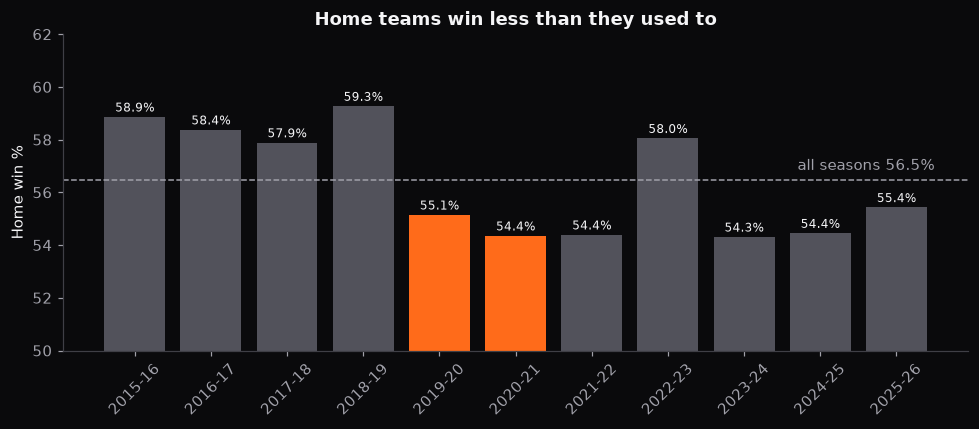

In [2]:
home = reg[~reg.is_neutral].groupby("season").home_win.agg(["mean", "size"])
overall = reg[~reg.is_neutral].home_win.mean()

fig, ax = plt.subplots(figsize=(9, 4))
colors = [ACCENT if s in ("2019-20", "2020-21") else "#52525B" for s in home.index]
ax.bar(home.index, home["mean"] * 100, color=colors)
ax.axhline(overall * 100, color=MUTED, ls="--", lw=1)
ax.text(len(home) - 0.5, overall * 100 + 0.4, f"all seasons {overall:.1%}", ha="right", color=MUTED)
ax.set_ylim(50, 62)
ax.set_ylabel("Home win %")
ax.set_title("Home teams win less than they used to")
ax.tick_params(axis="x", rotation=45)
for x, (_s, row) in enumerate(home.iterrows()):
    ax.text(x, row["mean"] * 100 + 0.2, f"{row['mean']:.1%}", ha="center", fontsize=8, color=TEXT)
save(fig, "home_win_rate_by_season")
home.assign(mean=lambda d: (d["mean"] * 100).round(1)).rename(
    columns={"mean": "home_win_%", "size": "games"}
)

The bubble (2019-20, partly played with no home teams) and the 2020-21 season of empty or limited
arenas stand out. The rate mostly stayed down afterwards: 54–55% in every season since except
2022-23 (58.0%), against 58–59% before 2019.
**Implication:** weight recent seasons, or let the model learn a season-varying home edge, instead of
hard-coding one from the full history.

## 2. Score distributions

margin sd 14.7 pts; 26.2% of games decided by 5 or fewer; 5.4% go to overtime


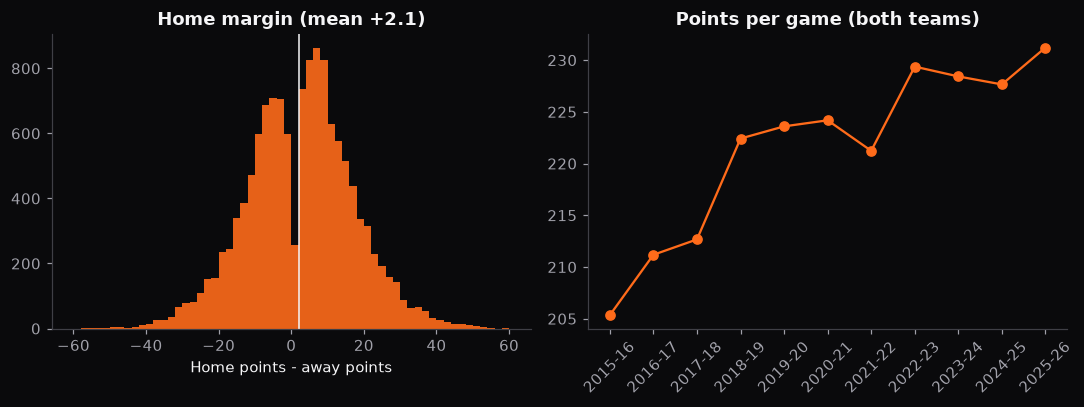

In [3]:
reg = reg.assign(total=reg.home_pts + reg.away_pts, margin=reg.home_pts - reg.away_pts)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
ax.hist(reg.margin, bins=np.arange(-60, 61, 2), color=ACCENT, alpha=0.9)
ax.axvline(reg.margin.mean(), color=TEXT, lw=1)
ax.set_title(f"Home margin (mean {reg.margin.mean():+.1f})")
ax.set_xlabel("Home points - away points")

ax = axes[1]
by_season = reg.groupby("season").total.mean()
ax.plot(by_season.index, by_season.values, marker="o", color=ACCENT)
ax.set_title("Points per game (both teams)")
ax.tick_params(axis="x", rotation=45)
save(fig, "score_distributions")

share_close = (reg.margin.abs() <= 5).mean()
print(
    f"margin sd {reg.margin.std():.1f} pts; {share_close:.1%} of games decided by 5 or fewer; "
    f"{(reg.overtimes > 0).mean():.1%} go to overtime"
)

Combined scoring rose from about 205 points a game in 2015-16 to about 231 in 2025-26 (faster pace,
more threes, better efficiency), so raw point totals aren't comparable across seasons. **Implication:** use per-possession ratings (offensive and defensive
rating, net rating) and season-relative features rather than raw points.

## 3. Rest and back-to-backs

Rest days = days since the team's previous game in the same season (1 = back-to-back). The first game
of a season has no rest value. This only uses dates known before tip-off.

,home_win_%,games
rest_diff,,
-3.0,46.8,47
-2.0,51.7,429
-1.0,53.6,2117
0.0,55.8,6824
1.0,59.2,2819
2.0,64.3,686
3.0,54.1,111


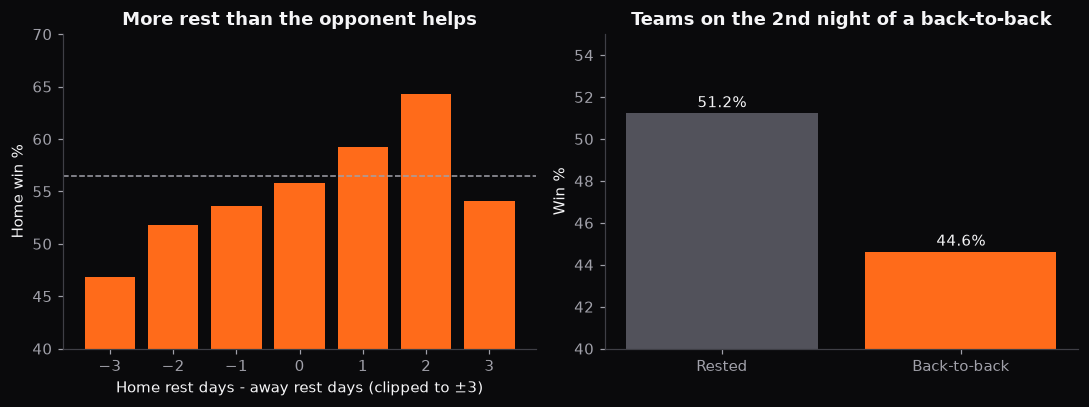

In [4]:
tg = team_games[team_games.season_type == "regular"].sort_values(["team_id", "game_date"]).copy()
tg["rest"] = tg.groupby(["team_id", "season"]).game_date.diff().dt.days
tg["rest_c"] = tg.rest.clip(upper=4)

wide = tg.pivot_table(index="game_id", columns="is_home", values="rest_c")
wide.columns = ["away_rest", "home_rest"]
g = reg.set_index("game_id").join(wide, how="inner").dropna(subset=["away_rest", "home_rest"])
g["rest_diff"] = (g.home_rest - g.away_rest).clip(-3, 3)

by_diff = g.groupby("rest_diff").home_win.agg(["mean", "size"])
b2b = tg.dropna(subset=["rest"]).assign(b2b=lambda d: d.rest == 1).groupby("b2b").win.mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
ax.bar(by_diff.index.astype(int), by_diff["mean"] * 100, color=ACCENT)
ax.axhline(g.home_win.mean() * 100, color=MUTED, ls="--", lw=1)
ax.set_ylim(40, 70)
ax.set_xlabel("Home rest days - away rest days (clipped to ±3)")
ax.set_ylabel("Home win %")
ax.set_title("More rest than the opponent helps")

ax = axes[1]
ax.bar(["Rested", "Back-to-back"], [b2b[False] * 100, b2b[True] * 100], color=["#52525B", ACCENT])
ax.set_ylim(40, 55)
ax.set_ylabel("Win %")
ax.set_title("Teams on the 2nd night of a back-to-back")
for x, v in enumerate([b2b[False], b2b[True]]):
    ax.text(x, v * 100 + 0.3, f"{v:.1%}", ha="center")
save(fig, "rest_effects")
by_diff.assign(mean=lambda d: (d["mean"] * 100).round(1)).rename(
    columns={"mean": "home_win_%", "size": "games"}
)

The home win rate climbs from 46.8% when the home team has 3 fewer rest days to 64.3% with 2 more.
The +3 bucket dips to 54.1%, but it's only 111 games. Teams on the second night of a back-to-back win
44.6% of the time against 51.2% otherwise, a gap of about 6.6 points. **Implication:** rest difference and back-to-back flags (ML_PLAN §3,
Schedule group) are worth building. Travel and time zones may add to it.

## 4. Pace over time

,pace,off_rating
season,,
2015-16,96.6,105.6
2016-17,97.0,108.2
2017-18,98.0,107.9
2018-19,100.7,109.7
2019-20,100.8,110.1
2020-21,99.8,111.7
2021-22,98.8,111.4
2022-23,99.8,114.1
2023-24,99.2,114.6


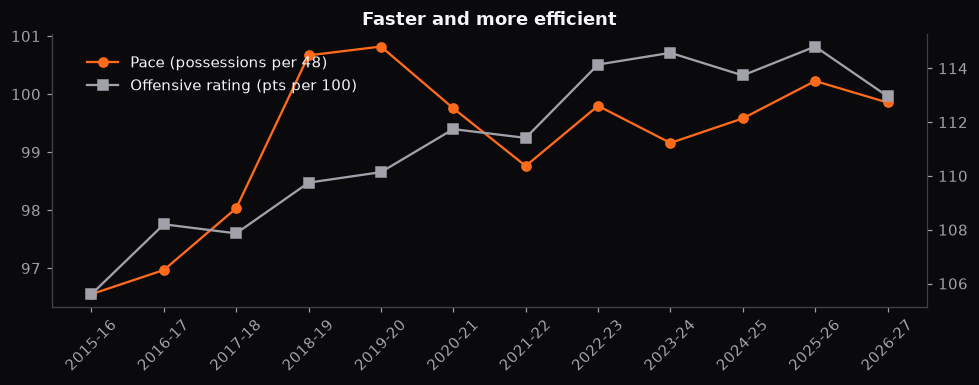

In [5]:
pace = (
    team_games[team_games.season_type == "regular"].groupby("season")[["pace", "off_rating"]].mean()
)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(pace.index, pace.pace, marker="o", color=ACCENT, label="Pace (possessions per 48)")
ax2 = ax.twinx()
ax2.plot(
    pace.index, pace.off_rating, marker="s", color=MUTED, label="Offensive rating (pts per 100)"
)
ax2.spines["right"].set_visible(True)
ax.set_title("Faster and more efficient")
ax.tick_params(axis="x", rotation=45)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88), frameon=False)
save(fig, "pace_and_efficiency")
pace.round(1)

## Takeaways for Phase 2

1. Home teams have won 54–55% in most recent seasons (2022-23 was the exception at 58%). Make sure the baselines and Elo's home-advantage
   constant are tuned on recent data.
2. Use per-possession, season-relative stats; raw points drift a lot over time.
3. Rest and back-to-backs show clear signal. Build them early.
4. 2019-20 and 2020-21 are unusual (bubble, 72 games, no fans). Consider flags or down-weighting.
5. 11 neutral-site games are flagged with `is_neutral`; home-court features should be zero for them.